In [ ]:
!pip install open-clip-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.0 MB/s eta 0:00:00


extra_timm_models.py:   0%|          | 0.00/9.89k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/nvidia/C-RADIOv4-H:
- extra_timm_models.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dinov2_arch.py:   0%|          | 0.00/35.5k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/nvidia/C-RADIOv4-H:
- dinov2_arch.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


enable_damp.py:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

...

[transformers] A new version of the following files was downloaded from https://huggingface.co/nvidia/C-RADIOv4-H:
- eradio_model.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/nvidia/C-RADIOv4-H:
- open_clip_adaptor.py
- extra_timm_models.py
- dinov2_arch.py
- enable_damp.py
- vitdet.py
- eradio_model.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.61GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/331 [00:00<?, ?B/s]

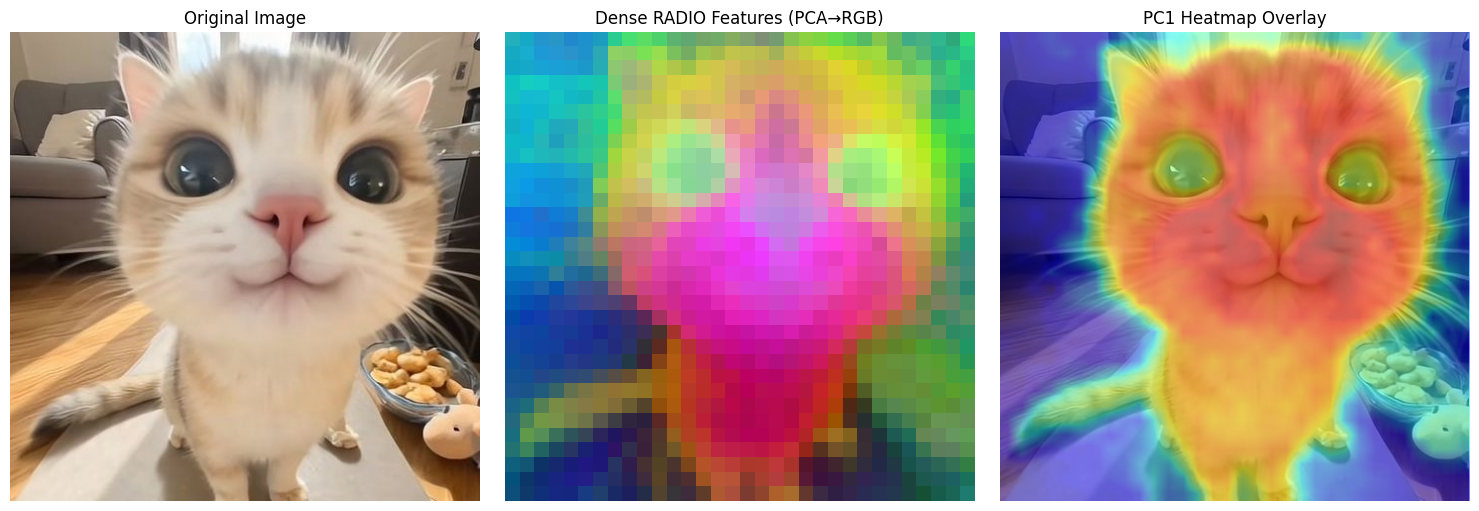

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import AutoModel, CLIPImageProcessor
from PIL import Image

# --- 1. Extract dense features with RADIO ---
model_name = "nvidia/C-RADIOv4-H"   # or "nvidia/C-RADIOv4-SO400M", "nvidia/C-RADIOv3-H", "nvidia/RADIO-L"
model = AutoModel.from_pretrained(model_name, trust_remote_code=True).eval()
processor = CLIPImageProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt", do_resize=True)

with torch.no_grad():
    # RADIO returns (summary, features) tuple
    summary, features = model(inputs["pixel_values"])

# features: [B, T, D] — spatial patch tokens already (no CLS token to skip)
B, N, D = features.shape

# Compute grid size from actual input dimensions and model patch size
# RADIOv4 uses patch_size=16; older RADIOv1 uses patch_size=14
patch_size = getattr(model.config, "patch_size", 16)
pixel_values = inputs["pixel_values"]
_, _, H, W = pixel_values.shape
grid_h = H // patch_size
grid_w = W // patch_size

features_np = features[0].numpy()    # [N, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(features_np)   # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_h, grid_w, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense RADIO Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_h, grid_w)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("radio_dense_features.png", dpi=150)
plt.show()